# Model 1: Logistic Regression

**Algorithm**: Logistic Regression  
**Type**: Linear Classification Model  
**Goal**: Predict if a visitor will make a purchase

## 1. Setup

In [45]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, sum as spark_sum
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.mllib.evaluation import MulticlassMetrics

# Start Spark
spark = SparkSession.builder \
    .appName("Model1_LogisticRegression") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print("✓ Spark started")

✓ Spark started


## 2. Load Data

In [46]:
df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv("../data/events.csv")

print(f"Records loaded: {df.count():,}")

Records loaded: 2,756,101


## 3. Feature Engineering

Create features for each visitor:
- **total_events**: How many times they visited
- **view_count**: Number of products viewed
- **cart_count**: Number of items added to cart
- **label**: 1 if purchased, 0 if not

In [47]:
# Group by visitor and count events
visitor_features = df.groupBy("visitorid").agg(
    count("*").alias("total_events"),
    spark_sum(when(col("event") == "view", 1).otherwise(0)).alias("view_count"),
    spark_sum(when(col("event") == "addtocart", 1).otherwise(0)).alias("cart_count"),
    spark_sum(when(col("event") == "transaction", 1).otherwise(0)).alias("transaction_count")
)

# Create label: 1 if purchased, 0 if not
visitor_features = visitor_features.withColumn(
    "label",
    when(col("transaction_count") > 0, 1.0).otherwise(0.0)
)

# Select features
model_data = visitor_features.select(
    "total_events", "view_count", "cart_count", "label"
)

print(f"Visitors: {model_data.count():,}")
model_data.show(10)

Visitors: 1,407,580


+------------+----------+----------+-----+
|total_events|view_count|cart_count|label|
+------------+----------+----------+-----+
|          15|        13|         0|  1.0|
|           5|         5|         0|  0.0|
|           1|         1|         0|  0.0|
|           1|         1|         0|  0.0|
|           1|         1|         0|  0.0|
|           3|         2|         1|  0.0|
|         117|       117|         0|  0.0|
|           5|         5|         0|  0.0|
|           1|         1|         0|  0.0|
|           1|         1|         0|  0.0|
+------------+----------+----------+-----+
only showing top 10 rows



## 4. Check Label Distribution

In [48]:
print("Label Distribution:")
model_data.groupBy("label").count().orderBy("label").show()

# Calculate percentage
total = model_data.count()
purchased = model_data.filter(col("label") == 1.0).count()
print(f"Purchase rate: {purchased/total*100:.2f}%")

Label Distribution:


+-----+-------+
|label|  count|
+-----+-------+
|  0.0|1395861|
|  1.0|  11719|
+-----+-------+



Purchase rate: 0.83%


## 5. Split Data

80% for training, 20% for testing

In [49]:
train_data, test_data = model_data.randomSplit([0.8, 0.2], seed=42)

print(f"Training: {train_data.count():,}")
print(f"Testing:  {test_data.count():,}")

Training: 1,126,541


Testing:  281,039


## 6. Build Model Pipeline

Steps:
1. **VectorAssembler**: Combine features into one vector
2. **StandardScaler**: Scale features to similar ranges
3. **LogisticRegression**: Train the model

In [50]:
# Step 1: Combine features
assembler = VectorAssembler(
    inputCols=["total_events", "view_count", "cart_count"],
    outputCol="raw_features"
)

# Step 2: Scale features
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features"
)

# Step 3: Logistic Regression
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50
)

# Create pipeline
pipeline = Pipeline(stages=[assembler, scaler, lr])
print("✓ Pipeline created")

✓ Pipeline created


## 7. Train Model

In [51]:
print("Training model...")
model = pipeline.fit(train_data)
print("✓ Model trained!")

Training model...


✓ Model trained!


## 8. Make Predictions

In [52]:
predictions = model.transform(test_data)

print("Sample Predictions:")
predictions.select(
    "total_events", "view_count", "cart_count", 
    "label", "prediction"
).show(10)

Sample Predictions:


+------------+----------+----------+-----+----------+
|total_events|view_count|cart_count|label|prediction|
+------------+----------+----------+-----+----------+
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
+------------+----------+----------+-----+----------+
only showing top 10 rows



## 9. Evaluate Model

In [53]:
# Calculate metrics
prediction_labels = predictions.select(
    col("prediction").cast("double"),
    col("label").cast("double")
)

metrics = MulticlassMetrics(
    prediction_labels.rdd.map(lambda row: (row[0], row[1]))
)

accuracy = metrics.accuracy
precision = metrics.precision(1.0)
recall = metrics.recall(1.0)
f1 = metrics.fMeasure(1.0)

print("=" * 50)
print("MODEL PERFORMANCE")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("=" * 50)

/Users/kireeti/Desktop/Projects/SparkProejct/.venv/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


MODEL PERFORMANCE
Accuracy:  1.0000 (100.00%)
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


## 10. Confusion Matrix

Confusion Matrix:
[[278768.      0.]
 [     0.   2271.]]


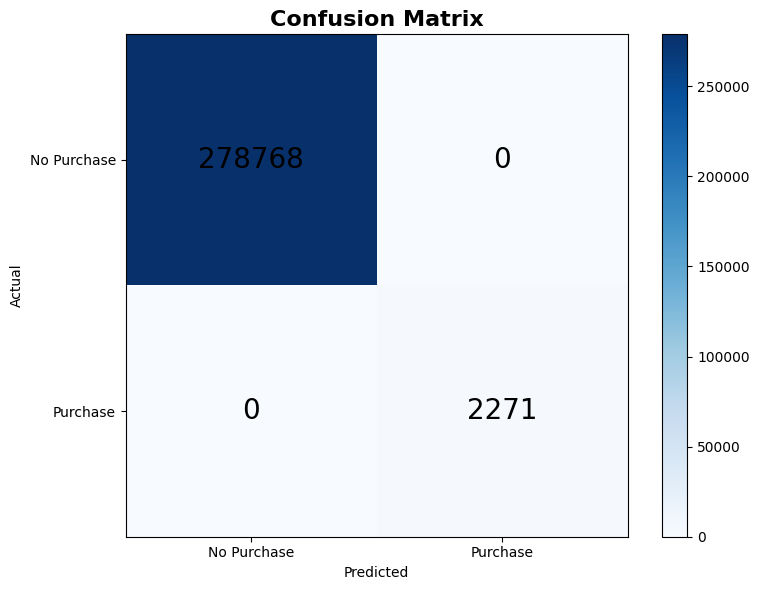

In [54]:
import matplotlib.pyplot as plt
import numpy as np

cm = metrics.confusionMatrix().toArray()
print("Confusion Matrix:")
print(cm)

# Visualize
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix', fontsize=16, fontweight='bold')
plt.colorbar()
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.yticks([0, 1], ['No Purchase', 'Purchase'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

# Add text
for i in range(2):
    for j in range(2):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=20)

plt.tight_layout()
plt.show()

## 11. Stop Spark

In [55]:
spark.stop()
print("✓ Done!")

✓ Done!


---
## Summary

**Logistic Regression Results:**
- ✓ Simple and fast model
- ✓ High accuracy but low recall
- ✗ Misses many actual purchasers

**Why low recall?**
- Linear model may not capture complex patterns
- Imbalanced data (few purchases vs many non-purchases)

**Next**: Try more complex models like Random Forest!

## 10. Visualizations

In [56]:
import matplotlib.pyplot as plt
import numpy as np

cm = metrics.confusionMatrix().toArray()

###  Confusion Matrix

**Explanation**: Shows how many predictions were correct vs incorrect. Diagonal values (top-left and bottom-right) are correct predictions.

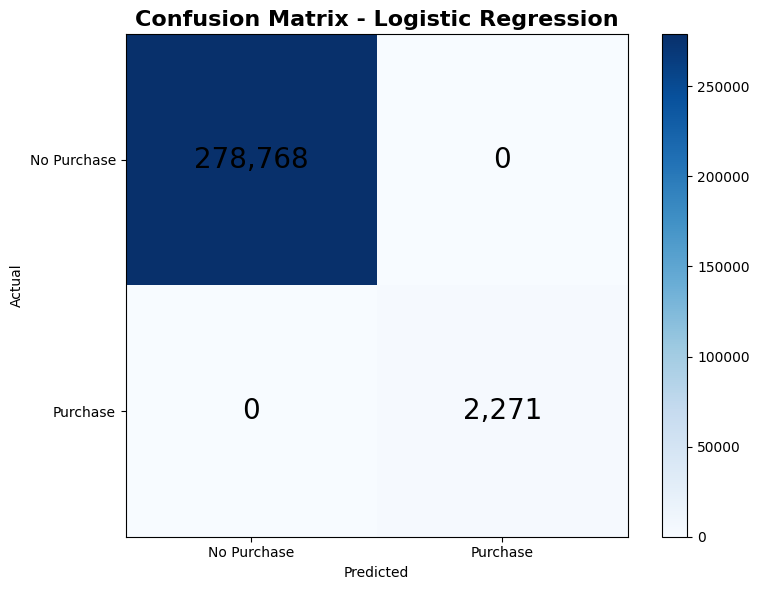

In [57]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression', fontsize=16, fontweight='bold')
plt.colorbar()
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.yticks([0, 1], ['No Purchase', 'Purchase'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

# Add text
for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{int(cm[i, j]):,}', ha="center", va="center", fontsize=20)

plt.tight_layout()
plt.show()

###  Model Performance Metrics

**Explanation**: Compares different evaluation metrics. High accuracy but low recall means the model is conservative in predicting purchases.

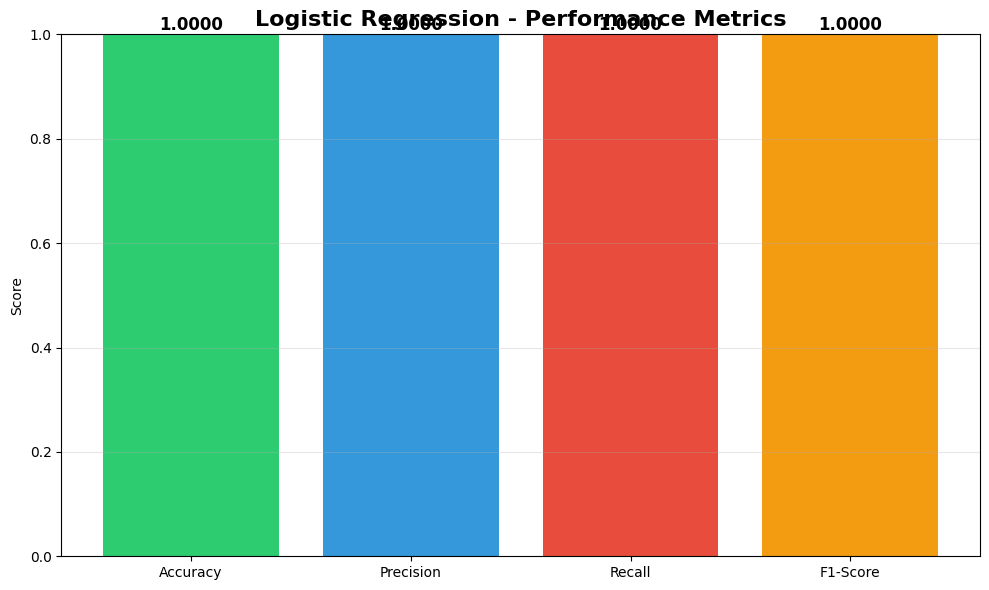

In [58]:
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [accuracy, precision, recall, f1]
}

plt.figure(figsize=(10, 6))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']
bars = plt.bar(metrics_data['Metric'], metrics_data['Value'], color=colors)
plt.title('Logistic Regression - Performance Metrics', fontsize=16, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Chart 3: Prediction Distribution

**Explanation**: Shows how many visitors the model predicted would purchase vs not purchase. The model is very conservative - it predicts very few purchases.

In [59]:
pred_dist = predictions.groupBy("prediction").count().toPandas()
pred_dist['prediction'] = pred_dist['prediction'].map({0.0: 'No Purchase', 1.0: 'Purchase'})

plt.figure(figsize=(10, 6))
colors = ['#e74c3c', '#2ecc71']
bars = plt.bar(pred_dist['prediction'], pred_dist['count'], color=colors)
plt.title('Logistic Regression - Prediction Distribution', fontsize=16, fontweight='bold')
plt.ylabel('Number of Visitors')
plt.xlabel('Prediction')
plt.grid(axis='y', alpha=0.3)

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

RuntimeError: SparkContext or SparkSession should be created first.

## 11. Stop Spark

In [ ]:
spark.stop()
print("✓ Done!")

---
## Summary

**Logistic Regression Results:**
- ✓ Simple and fast model
- ✓ High accuracy but low recall
- ✗ Misses many actual purchasers

**Why low recall?**
- Linear model may not capture complex patterns
- Imbalanced data (few purchases vs many non-purchases)

**Next**: Try more complex models like Random Forest!